# HERMES final AutoDL — fresh clone, new experiments, consolidated reanalysis

**For a new AutoDL container after cloning `md-hameem/HERMES-reproduction`.** The notebook uses official source at the repository root and the preserved AutoDL evidence under `HERMES/results/`, `logs/`, and `exports/`. The historical root `results/` tree is not used as AutoDL evidence.

The original HERMES 4K/6K/50K inference is **never rerun**. Its 750 predictions and logs are hash-checked and reused. Only missing environment, model, or video assets are installed/downloaded. New work is limited to identical-environment HERMES 4K/6K repeats, pseudo-query attention differential validation, and FIFO 4K/6K controls; all existing and new results are then reanalyzed together.

Default clone path: `/root/autodl-tmp/HERMES-reproduction`. Optional overrides: set the `HERMES_REPO` and `HERMES_WORK` environment variables before Run All. Keep `EXECUTION_MODE='full'` for the research suite. Rerunning reuses only complete, validated new outputs; partial or malformed evidence stops for inspection. Actual GPU success is determined only by observed outputs and final integrity checks.

## 1. Configuration and AutoDL preflight

In [1]:
!source /etc/network_turbo

设置成功!
注意：
1. 仅限学术用途和加速访问github/huggingface，不承诺稳定性
2. 开启加速后对访问其他资源如pip源等会*更慢*


In [2]:
# Bootstrap packages used by the Jupyter notebook itself, before importing them.
import sys, subprocess, importlib.util
_kernel_requirements = {
    'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy',
    'matplotlib': 'matplotlib', 'requests': 'requests',
}
_missing = [package for module, package in _kernel_requirements.items()
            if importlib.util.find_spec(module) is None]
if _missing:
    print('Installing missing notebook-kernel packages:', ', '.join(_missing), flush=True)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        '-i', 'https://pypi.tuna.tsinghua.edu.cn/simple', *_missing])
print('Notebook-kernel dependencies ready.', flush=True)

from pathlib import Path
import os, sys, subprocess, json, re, zipfile, hashlib, shutil, time, copy, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.stats import binomtest
import matplotlib.pyplot as plt
from IPython.display import display
import requests

MODEL_ID = 'llava-hf/llava-onevision-qwen2-0.5b-ov-hf'
MODEL_SHA = '74dd0bf867a4cda7950c17663794267c60cf4b40'
HERMES_URL = 'https://github.com/haowei-freesky/HERMES.git'
HERMES_SHA = '8d699b16a6bedb9086c1b39ec4253c6a1d1ce789'
TF_SHA = '66bc4def9505fa7c7fe4aa7a248c34a026bb552b'
DATASET_ID = 'mjuicem/StreamingBench'
FPS, SEED = 0.5, 2024
KV_BUDGETS = (4000, 6000, 50000)
BOOTSTRAP_REPS = 10000
EXECUTION_MODE = 'full'  # 'full' or 'smoke'
assert EXECUTION_MODE in {'full','smoke'}
MIN_FREE_GIB, MIN_VRAM_GIB = 35, 15

ROOT = Path(os.environ.get('HERMES_REPO', '/root/autodl-tmp/HERMES-reproduction')).expanduser().resolve()
WORK = Path(os.environ.get('HERMES_WORK', '/root/autodl-tmp/hermes_final_new')).expanduser().resolve()
REPO = ROOT
assert ROOT.is_dir(), f'Clone the repository first; not found: {ROOT}'
for rel in ('inference/llavaov_hermes.py', 'video_qa/hermes_vqa.py',
            'data/streamingbench/streamingbench_realtime.json',
            'HERMES/results', 'logs', 'exports'):
    assert (ROOT/rel).exists(), f'Missing expected cloned-repository path: {ROOT/rel}'
assert WORK != ROOT and ROOT not in WORK.parents and WORK not in ROOT.parents, 'WORK must be separate and not nested with the cloned repository.'

# Preserved evidence is read-only input. New predictions and regenerated analysis live under WORK.
ORIGINAL_RESULTS = ROOT/'HERMES'/'results'
ORIGINAL_LOGS = ROOT/'logs'
ORIGINAL_EXPORTS = ROOT/'exports'
RESULTS, DATA = WORK/'results', WORK/'data'
EXPORTS, FIGURES = WORK/'exports', WORK/'exports'/'figures'
LOGS = WORK/'logs'
VENV = WORK/'venvs'/'hermes-py312'
PY312 = VENV/'bin'/'python'
ARCHIVE_CACHE = WORK/'downloads'
VIDEO_DIR = WORK/'videos'/'streamingbench_201_250'
HF_HOME = WORK/'cache'/'huggingface'
MODEL_CACHE = HF_HOME/'hub'
UV_CACHE = WORK/'cache'/'uv'
MODEL_DIR = ROOT/'models'/'llava-onevision-qwen2-0.5b-ov-hf'
EXPECTED_MODEL_SNAPSHOT = MODEL_CACHE/'models--llava-hf--llava-onevision-qwen2-0.5b-ov-hf'/'snapshots'/MODEL_SHA
for directory in (WORK, RESULTS, DATA, EXPORTS, FIGURES, LOGS, ARCHIVE_CACHE,
                  VIDEO_DIR, HF_HOME, MODEL_CACHE, UV_CACHE):
    directory.mkdir(parents=True, exist_ok=True)

def run(args, *, cwd=None, env=None, check=True):
    proc = subprocess.run([str(a) for a in args], cwd=cwd, env=env,
                          text=True, capture_output=True)
    if check and proc.returncode:
        raise RuntimeError('Command failed: ' + repr(args) + '\n' + (proc.stdout + proc.stderr)[-6000:])
    return proc

def run_live(args, *, cwd=None, env=None):
    # Long downloads show their own progress instead of appearing idle behind captured output.
    proc = subprocess.run([str(a) for a in args], cwd=cwd, env=env)
    if proc.returncode:
        raise RuntimeError(f'Command failed with return code {proc.returncode}: {args!r}')
    return proc

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def result_path(kv):
    return ORIGINAL_RESULTS/f'streamingbench_50_kv{kv}'/'1_0.csv'

def original_log_path(kv):
    return ORIGINAL_LOGS/f'streamingbench_50_kv{kv}.log'

assert Path('/root/autodl-tmp').is_dir(), 'AutoDL data disk /root/autodl-tmp is missing.'
free_gib = shutil.disk_usage(WORK).free/1024**3
assert free_gib >= MIN_FREE_GIB, f'Only {free_gib:.1f} GiB free; free at least {MIN_FREE_GIB} GiB.'
smi = run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'], check=False)
assert smi.returncode == 0 and smi.stdout.strip(), 'No NVIDIA GPU visible: ' + smi.stderr
print('GPU:', smi.stdout.strip())
mem_mib = float(re.search(r'(\d+(?:\.\d+)?)\s*MiB', smi.stdout).group(1))
assert mem_mib/1024 >= MIN_VRAM_GIB, f'GPU has {mem_mib/1024:.1f} GiB; at least {MIN_VRAM_GIB} GiB required.'
print('Notebook Python:', sys.version.split()[0])
print('Cloned repository:', ROOT)
print('New persistent work directory:', WORK, '| free:', round(free_gib, 1), 'GiB')
print('Original HERMES inference: DISABLED; preserved CSVs will be validated and reused.')

# Capture AutoDL academic-network proxy settings, when available, for all children.
def network_environment():
    env = os.environ.copy(); turbo = Path('/etc/network_turbo')
    if turbo.is_file():
        proc = subprocess.run(['bash','-lc','source /etc/network_turbo >/dev/null 2>&1; env -0'], capture_output=True)
        if proc.returncode == 0:
            for item in proc.stdout.split(b'\0'):
                if b'=' in item:
                    key, value = item.split(b'=',1)
                    env[key.decode()] = value.decode()
    return env
NETWORK_ENV = network_environment()

def download_archive(urls, dest, retries=4):
    """Resumable HTTP download with explicit failure and optional alternate URLs."""
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if isinstance(urls, str): urls = [urls]
    errors = []
    for url in urls:
        for attempt in range(1, retries+1):
            try:
                headers = {}; mode = 'wb'
                if dest.exists() and dest.stat().st_size:
                    headers['Range'] = f'bytes={dest.stat().st_size}-'; mode = 'ab'
                with requests.Session() as session:
                    for key in ('HTTP_PROXY','HTTPS_PROXY','ALL_PROXY','NO_PROXY',
                                'http_proxy','https_proxy','all_proxy','no_proxy'):
                        if key in NETWORK_ENV: session.proxies[key] = NETWORK_ENV[key]
                    with session.get(url, headers=headers, stream=True, timeout=(30,120)) as response:
                        if response.status_code == 416 and dest.exists(): return dest
                        if response.status_code != 206: mode = 'wb'
                        response.raise_for_status()
                        with open(dest, mode) as handle:
                            for chunk in response.iter_content(1024*1024):
                                if chunk: handle.write(chunk)
                assert dest.stat().st_size > 0
                print('Downloaded:', dest, 'bytes:', dest.stat().st_size, flush=True)
                return dest
            except Exception as exc:
                errors.append(f'{url} attempt {attempt}: {exc}')
                print(errors[-1], flush=True); time.sleep(min(20,3*attempt))
    raise RuntimeError('Archive download failed:\n' + '\n'.join(errors[-8:]))

Installing missing notebook-kernel packages: pandas, scipy


Notebook-kernel dependencies ready.
GPU: NVIDIA GeForce RTX 4080, 32760 MiB, 595.71.05
Notebook Python: 3.12.3
Cloned repository: /root/autodl-tmp/HERMES-reproduction
New persistent work directory: /root/autodl-tmp/hermes_final_new | free: 49.2 GiB
Original HERMES inference: DISABLED; preserved CSVs will be validated and reused.


## 2. Reuse or create the pinned Python 3.12 inference environment

A valid existing environment is left untouched. On a fresh container, missing packages and the pinned Transformers source archive are installed automatically; AutoDL’s system Python and Jupyter kernel are not replaced.

In [5]:
uv_install([
    'torch @ https://download-r2.pytorch.org/whl/cu128/torch-2.10.0%2Bcu128-cp312-cp312-manylinux_2_28_x86_64.whl'
])

m
 + cuda-bindings==12.9.4
 + cuda-pathfinder==1.8.4
 + filelock==4.2.4
 + fsspec==2026.9.0
 + jinja2==3.1.6
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.7
 + nvidia-cublas-cu12==12.8.4.1
 + nvidia-cuda-cupti-cu12==12.8.90
 + nvidia-cuda-nvrtc-cu12==12.8.93
 + nvidia-cuda-runtime-cu12==12.8.90
 + nvidia-cudnn-cu12==9.10.2.21
 + nvidia-cufft-cu12==11.3.3.83
 + nvidia-cufile-cu12==1.13.1.3
 + nvidia-curand-cu12==10.3.9.90
 + nvidia-cusolver-cu12==11.7.3.90
 + nvidia-cusparse-cu12==12.5.8.93
 + nvidia-cusparselt-cu12==0.7.1
 + nvidia-nccl-cu12==2.27.5
 + nvidia-nvjitlink-cu12==12.8.93
 + nvidia-nvshmem-cu12==3.4.5
 + nvidia-nvtx-cu12==12.8.90
 + setuptools==84.2.1
 + sympy==1.14.0
 + torch==2.10.0+cu128 (from https://download-r2.pytorch.org/whl/cu128/torch-2.10.0%2Bcu128-cp312-cp312-manylinux_2_28_x86_64.whl)
 + triton==3.6.0
 + typing-extensions==4.16.0



In [6]:
# Probe first so a rerun does not reinstall an already valid environment.
_env_probe = r"""
import sys, json, torch, transformers, tokenizers, huggingface_hub
import importlib.metadata as md
assert sys.version_info[:2] == (3,12)
assert torch.__version__ == '2.10.0+cu128'
assert transformers.__version__ == '4.45.0.dev0'
assert tokenizers.__version__ == '0.19.1'
assert huggingface_hub.__version__ == '0.34.4'
meta = json.loads(md.distribution('transformers').read_text('direct_url.json'))
if 'vcs_info' in meta:
    assert meta['vcs_info']['commit_id'] == '66bc4def9505fa7c7fe4aa7a248c34a026bb552b'
else:
    assert '66bc4def9505fa7c7fe4aa7a248c34a026bb552b' in meta.get('url','')
import decord, logzero, pandas, scipy, av
"""
_env_ok = PY312.is_file() and run([PY312,'-c',_env_probe], check=False).returncode == 0
if _env_ok:
    print('Reusing validated pinned environment; no packages reinstalled:', PY312)
else:
    print('Pinned environment missing or incomplete; installing/repairing it now.', flush=True)
    try:
        run([sys.executable,'-m','uv','--version'])
    except RuntimeError:
        run([sys.executable,'-m','pip','install','-q',
             '-i','https://pypi.tuna.tsinghua.edu.cn/simple','uv'])
    UV = [sys.executable,'-m','uv']
    INSTALL_ENV = {**NETWORK_ENV, 'UV_CACHE_DIR':str(UV_CACHE), 'UV_LINK_MODE':'copy',
                   'TMPDIR':str(WORK), 'UV_DEFAULT_INDEX':'https://pypi.tuna.tsinghua.edu.cn/simple'}
    if not PY312.exists():
        run(UV+['venv',str(VENV),'--python','3.12','--seed'], env=INSTALL_ENV)
    assert '3.12.' in run([PY312,'--version']).stdout
    def uv_install(packages, extra_args=()):
        proc = run(UV+['pip','install','--python',str(PY312)]+list(extra_args)+list(packages), env=INSTALL_ENV)
        if proc.stderr: print(proc.stderr[-1600:])
    uv_install(['torch==2.10.0+cu128'], ['--index-url','https://download.pytorch.org/whl/cu128'])
    uv_install(['numpy==1.26.4','tokenizers==0.19.1','huggingface-hub==0.34.4',
        'accelerate==0.34.2','decord==0.6.0','logzero','pillow','sentencepiece',
        'safetensors','packaging','filelock','regex','requests','pyyaml','tqdm',
        'fsspec','protobuf','einops','psutil','pandas','scipy','av'])
    tf_archive = ARCHIVE_CACHE/f'transformers-{TF_SHA}.zip'
    if not tf_archive.is_file() or not zipfile.is_zipfile(tf_archive):
        tf_archive.unlink(missing_ok=True)
        download_archive([f'https://codeload.github.com/huggingface/transformers/zip/{TF_SHA}',
                          f'https://github.com/huggingface/transformers/archive/{TF_SHA}.zip'], tf_archive)
    assert zipfile.is_zipfile(tf_archive), tf_archive
    uv_install([str(tf_archive)], ['--no-deps'])
    print('Pinned environment installed:', PY312)

Pinned environment missing or incomplete; installing/repairing it now.
Using Python 3.12.3 environment at: /root/autodl-tmp/hermes_final_new/venvs/hermes-py312
Checked 1 package in 7ms

Using Python 3.12.3 environment at: /root/autodl-tmp/hermes_final_new/venvs/hermes-py312
Resolved 56 packages in 3.42s
Prepared 28 packages in 1.50s
Installed 28 packages in 854ms
 + accelerate==0.34.2
 + av==19.0.2
 + certifi==2026.10.23
 + charset-normalizer==3.5.2
 + decord==0.6.0
 + einops==0.8.2
 + hf-xet==1.7.0
 + huggingface-hub==0.34.4
 + idna==3.20
 + logzero==1.7.0
 + numpy==1.26.4
 + packaging==26.3
 + pandas==3.0.6
 + pillow==13.0.0
 + protobuf==7.36.2
 + psutil==7.2.2
 + python-dateutil==3.0.0
 + pyyaml==6.0.3
 + regex==2026.9.29
 + requests==2.34.2
 + safetensors==0.8.0
 + scipy==1.17.1
 + sentencepiece==0.2.2
 + six==1.17.0
 + tokenizers==0.19.1
 + tqdm==4.70.1
 + tzdata==2026.5
 + urllib3==2.8.0

Downloaded: /root/autodl-tmp/hermes_final_new/downloads/transformers-66bc4def9505fa7c7fe4aa7

In [7]:
check_code = r"""
import sys, json, inspect, torch, transformers, tokenizers, huggingface_hub
import importlib.metadata as md
from transformers.models.qwen2.modeling_qwen2 import Qwen2RotaryEmbedding
assert sys.version_info[:2] == (3, 12), sys.version
assert torch.__version__ == '2.10.0+cu128', torch.__version__
assert torch.cuda.is_available(), 'The inference interpreter cannot see CUDA'
assert transformers.__version__ == '4.45.0.dev0', transformers.__version__
assert tokenizers.__version__ == '0.19.1'
assert huggingface_hub.__version__ == '0.34.4'
meta = md.distribution('transformers').read_text('direct_url.json')
assert meta, 'Missing Transformers direct_url.json'
source_meta = json.loads(meta)
if 'vcs_info' in source_meta:
    assert source_meta['vcs_info']['commit_id'] == '66bc4def9505fa7c7fe4aa7a248c34a026bb552b'
else:
    assert '66bc4def9505fa7c7fe4aa7a248c34a026bb552b' in source_meta.get('url', ''), source_meta
assert 'seq_len' in str(inspect.signature(Qwen2RotaryEmbedding.forward))
print('Inference Python:', sys.executable)
print('Torch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))
print('Transformers:', transformers.__version__, '| pinned source: PASS')
"""
model_env = {**NETWORK_ENV, 'HF_HOME': str(HF_HOME), 'HF_HUB_DISABLE_XET': '1', 'HF_ENDPOINT': 'https://hf-mirror.com',
             'HF_HUB_ENABLE_HF_TRANSFER': '0', 'CUDA_VISIBLE_DEVICES': '0'}
print(run([PY312, '-c', check_code], env=model_env).stdout)

Inference Python: /root/autodl-tmp/hermes_final_new/venvs/hermes-py312/bin/python
Torch: 2.10.0+cu128 | GPU: NVIDIA GeForce RTX 4080
Transformers: 4.45.0.dev0 | pinned source: PASS



## 3. Verify cloned source against the pinned official HERMES revision

In [8]:
# The reproduction repository has its own Git HEAD; do not confuse it with official HERMES_SHA.
assert (ROOT/'.git').exists(), f'Expected a Git clone at {ROOT}'
REPRO_HEAD = run(['git','rev-parse','HEAD'], cwd=ROOT).stdout.strip()
SOURCE_PATHS = ['inference','video_qa','data/streamingbench/streamingbench_realtime.json']
source_commit = run(['git','cat-file','-e',HERMES_SHA+'^{commit}'], cwd=ROOT, check=False)
if source_commit.returncode == 0:
    diff = run(['git','diff','--name-only',HERMES_SHA,'--']+SOURCE_PATHS, cwd=ROOT).stdout.splitlines()
    assert not diff, f'Cloned source differs from pinned official HERMES: {diff}'
    untracked = run(['git','ls-files','--others','--exclude-standard','--','inference','video_qa'], cwd=ROOT).stdout.splitlines()
    unexpected = [x for x in untracked if not x.endswith('.pyc') and '__pycache__/' not in x]
    assert not unexpected, f'Unexpected untracked inference source: {unexpected}'
    SOURCE_VERIFICATION = f'git diff against official commit {HERMES_SHA}'
else:
    # Shallow reproduction clones may omit the official commit; compare a pinned archive instead.
    archive = ARCHIVE_CACHE/f'HERMES-{HERMES_SHA}.zip'
    if not archive.is_file() or not zipfile.is_zipfile(archive):
        archive.unlink(missing_ok=True)
        download_archive([f'https://codeload.github.com/haowei-freesky/HERMES/zip/{HERMES_SHA}',
                          f'https://github.com/haowei-freesky/HERMES/archive/{HERMES_SHA}.zip'], archive)
    assert zipfile.is_zipfile(archive), archive
    official_extract = WORK/'source_verify'/HERMES_SHA
    if official_extract.exists(): shutil.rmtree(official_extract)
    official_extract.mkdir(parents=True)
    with zipfile.ZipFile(archive) as z:
        base = official_extract.resolve()
        for item in z.infolist():
            target = (official_extract/item.filename).resolve()
            assert target == base or base in target.parents, item.filename
        z.extractall(official_extract)
    official_root = next(x for x in official_extract.iterdir() if x.is_dir())
    for area in ('inference','video_qa'):
        def source_files(base):
            return {str(x.relative_to(base)) for x in (base/area).rglob('*')
                    if x.is_file() and not x.name.endswith('.pyc') and '__pycache__' not in x.parts}
        assert source_files(ROOT) == source_files(official_root), f'Source file set differs in {area}'
        for rel in source_files(official_root):
            assert sha256(ROOT/rel) == sha256(official_root/rel), rel
    annotation_rel = 'data/streamingbench/streamingbench_realtime.json'
    assert sha256(ROOT/annotation_rel) == sha256(official_root/annotation_rel)
    SOURCE_VERIFICATION = f'byte comparison with official pinned archive {HERMES_SHA}'
for rel in ('inference/llavaov_hermes.py','inference/reindex_1d.py','video_qa/base.py',
            'data/streamingbench/streamingbench_realtime.json'):
    assert (ROOT/rel).is_file(), rel
    print(rel, sha256(ROOT/rel))
reindex_tail = (ROOT/'inference/reindex_1d.py').read_text().split('def apply_rotary_delta_to_keys_only')[-1][:230]
assert 'return key_states' not in reindex_tail, 'Disabled RoPE-delta debug patch detected.'
source_provenance = {'reproduction_repository':str(ROOT), 'reproduction_head':REPRO_HEAD,
                     'official_hermes_revision':HERMES_SHA, 'verification':SOURCE_VERIFICATION}
(WORK/'source_provenance.json').write_text(json.dumps(source_provenance,indent=2))
print('Reproduction HEAD:', REPRO_HEAD)
print('Official HERMES source fidelity: PASS |', SOURCE_VERIFICATION)

inference/llavaov_hermes.py 45fee483fbc37fe65433c84146eba42fc18dae40f6878c7a2f50fd8e55a387f0
inference/reindex_1d.py 22ca0dee63cd7a4d00161f1fc0485143a57145862b081555598b904bbc95e0b0
video_qa/base.py 795cf98e8d1125ea934dc2c9744ba1bbd3b29701f17aae2d935f382c7343b2d5
data/streamingbench/streamingbench_realtime.json 6a2969953e11db44f5f8584d0d9fd3ec47c41dacf63807ef0003ccf446869f73
Reproduction HEAD: af79580aab9c2e58b48432cc91088d374a0e0b04
Official HERMES source fidelity: PASS | git diff against official commit 8d699b16a6bedb9086c1b39ec4253c6a1d1ce789


## 4. Reuse or download the exact pinned model snapshot

In [9]:
def valid_model_directory(path):
    path = Path(path)
    return path.is_dir() and (path/'config.json').is_file() and bool(list(path.glob('*.safetensors')))

MODEL_SNAPSHOT = None
if valid_model_directory(EXPECTED_MODEL_SNAPSHOT):
    MODEL_SNAPSHOT = EXPECTED_MODEL_SNAPSHOT.resolve()
    print('Reusing model from persistent Hugging Face cache:', MODEL_SNAPSHOT)
elif MODEL_DIR.is_symlink() and valid_model_directory(MODEL_DIR):
    resolved = MODEL_DIR.resolve()
    assert resolved.name == MODEL_SHA, f'Unexpected model snapshot identity: {resolved}'
    MODEL_SNAPSHOT = resolved
    print('Reusing model through repository link:', MODEL_DIR)
else:
    if MODEL_DIR.exists() and not MODEL_DIR.is_symlink():
        if any(MODEL_DIR.iterdir()):
            raise RuntimeError(f'{MODEL_DIR} exists but is not a verified pinned cache link. Move it aside or use the HF cache; refusing to overwrite it.')
        MODEL_DIR.rmdir()  # safe: empty placeholder only
    model_downloader = WORK/'download_model.py'
    model_pointer = WORK/'model_snapshot_path.json'
    model_downloader.write_text(r"""
import json, sys
from huggingface_hub import snapshot_download
path = snapshot_download(repo_id=sys.argv[1], revision=sys.argv[2], cache_dir=sys.argv[3],
    allow_patterns=['*.json','*.safetensors','*.txt','*.model','*.vocab','tokenizer.*','merges.txt'],
    ignore_patterns=['onnx/*','*.onnx','*.bin','*.msgpack'])
with open(sys.argv[4],'w') as f: json.dump(str(path),f)
print('MODEL_SNAPSHOT=' + str(path), flush=True)
""")
    model_pointer.unlink(missing_ok=True)
    print('Model not found locally; downloading pinned snapshot with resumable Hugging Face cache.', flush=True)
    run_live([PY312,str(model_downloader),MODEL_ID,MODEL_SHA,str(MODEL_CACHE),str(model_pointer)], env=model_env)
    assert model_pointer.is_file(), 'Model downloader did not return a snapshot path.'
    MODEL_SNAPSHOT = Path(json.loads(model_pointer.read_text())).resolve()
assert valid_model_directory(MODEL_SNAPSHOT), 'Checkpoint config or weights missing.'
assert MODEL_SNAPSHOT.name == MODEL_SHA, MODEL_SNAPSHOT.name
MODEL_DIR.parent.mkdir(parents=True, exist_ok=True)
if MODEL_DIR.is_symlink() and MODEL_DIR.resolve() != MODEL_SNAPSHOT:
    MODEL_DIR.unlink()
if not MODEL_DIR.exists():
    MODEL_DIR.symlink_to(MODEL_SNAPSHOT, target_is_directory=True)
assert valid_model_directory(MODEL_DIR) and MODEL_DIR.resolve() == MODEL_SNAPSHOT
print('Model:', MODEL_DIR)
print('Resolved snapshot:', MODEL_SNAPSHOT)
print('Snapshot identity: PASS |', MODEL_SHA)

Model not found locally; downloading pinned snapshot with resumable Hugging Face cache.


Fetching 14 files:  93%|█████████▎| 13/14 [00:20<00:01,  1.54s/it]

MODEL_SNAPSHOT=/root/autodl-tmp/hermes_final_new/cache/huggingface/hub/models--llava-hf--llava-onevision-qwen2-0.5b-ov-hf/snapshots/74dd0bf867a4cda7950c17663794267c60cf4b40
Model: /root/autodl-tmp/HERMES-reproduction/models/llava-onevision-qwen2-0.5b-ov-hf
Resolved snapshot: /root/autodl-tmp/hermes_final_new/cache/huggingface/hub/models--llava-hf--llava-onevision-qwen2-0.5b-ov-hf/snapshots/74dd0bf867a4cda7950c17663794267c60cf4b40
Snapshot identity: PASS | 74dd0bf867a4cda7950c17663794267c60cf4b40


Fetching 14 files: 100%|██████████| 14/14 [01:36<00:00,  6.92s/it]


## 5. Reuse or download StreamingBench 201–250 and validate question identity

The preserved annotation’s old absolute paths are not reused. Video paths are rebuilt for this container, while `(video_id, qa_index)`, question text, choices, answers, and task metadata are cross-checked against both the official master annotation and the preserved 50-video annotation.

In [11]:
ANNOTATION_MASTER = ROOT/'data'/'streamingbench'/'streamingbench_realtime.json'
PRESERVED_ANNOTATION = ROOT/'HERMES'/'data'/'streamingbench_50_autodl.json'
annotations = json.loads(ANNOTATION_MASTER.read_text())
assert isinstance(annotations,list) and len(annotations) == 498
assert sum(len(x['conversations']) for x in annotations) == 2495
SHARD_50 = 'Real-Time Visual Understanding_201-250.zip'

def safe_extract(z, output_dir):
    output_dir = Path(output_dir); base = output_dir.resolve(); total = 0
    for item in z.infolist():
        target = (output_dir/item.filename).resolve()
        assert target == base or base in target.parents, 'ZIP path traversal: '+item.filename
        assert not item.is_dir() or not item.filename.startswith('/'), 'Unsafe ZIP entry'
        total += item.file_size
    assert total <= 30*1024**3, f'Archive expands to an unexpected {total/1024**3:.1f} GiB'
    z.extractall(output_dir)

def annotation_for_directory(path):
    candidates = {}
    for path_obj in Path(path).rglob('*'):
        if path_obj.is_file() and path_obj.suffix.lower() in {'.mp4','.avi','.mov','.mkv'} and not path_obj.name.startswith('._'):
            matches = re.findall(r'sample_(\d+)',str(path_obj))
            if matches:
                sample_id = int(matches[-1])
                assert sample_id not in candidates, f'Multiple videos for sample_{sample_id}'
                candidates[sample_id] = path_obj.resolve()
    mapped = []
    for item in annotations:
        match = re.search(r'sample_(\d+)_real\.mp4',str(item['video_path']))
        if match and 201 <= int(match.group(1)) <= 250 and int(match.group(1)) in candidates:
            record = copy.deepcopy(item)
            record['video_path'] = str(candidates[int(match.group(1))])
            mapped.append((int(match.group(1)),record))
    return [record for _,record in sorted(mapped,key=lambda x:x[0])]

# Reuse only a complete 50-video directory; a few stray MP4s do not count as a complete asset.
matched50 = []
for candidate in (VIDEO_DIR, ROOT/'data'/'streamingbench'/'videos',
                  ROOT/'HERMES'/'videos'/'streamingbench_201_250'):
    if candidate.is_dir():
        candidate_matches = annotation_for_directory(candidate)
        if len(candidate_matches) == 50:
            VIDEO_DIR = candidate.resolve(); matched50 = candidate_matches
            print('Reusing complete local video directory:', VIDEO_DIR)
            break
if not matched50:
    downloader = WORK/'download_shard.py'; archive_pointer = WORK/'video_archive_path.json'
    downloader.write_text(r"""
import sys, json
from huggingface_hub import hf_hub_download
path = hf_hub_download(repo_id=sys.argv[1],repo_type='dataset',filename=sys.argv[2],local_dir=sys.argv[3])
with open(sys.argv[4],'w') as f: json.dump(str(path),f)
print('ARCHIVE='+str(path),flush=True)
""")
    archive_pointer.unlink(missing_ok=True)
    print('Complete 50-video shard not found; downloading only the missing StreamingBench shard.', flush=True)
    run_live([PY312,str(downloader),DATASET_ID,SHARD_50,str(ARCHIVE_CACHE),str(archive_pointer)], env=model_env)
    archive = Path(json.loads(archive_pointer.read_text()))
    assert zipfile.is_zipfile(archive), archive
    with zipfile.ZipFile(archive) as z: safe_extract(z,VIDEO_DIR)
    matched50 = annotation_for_directory(VIDEO_DIR)
    assert len(matched50) == 50, f'Expected 50 matched videos after extraction, got {len(matched50)}'
    archive.unlink(missing_ok=True)
assert len(matched50) == 50 and sum(len(x['conversations']) for x in matched50) == 250
assert all(Path(x['video_path']).is_file() for x in matched50)

# Ignore only video_path when comparing with preserved evidence; all question metadata must match exactly.
def annotation_identity(records):
    return [{'video_id':x['video_id'],'conversations':x['conversations']} for x in records]
preserved50 = json.loads(PRESERVED_ANNOTATION.read_text())
assert annotation_identity(matched50) == annotation_identity(preserved50), 'Regenerated annotation differs from preserved evidence.'
ANNOTATION_50 = DATA/'streamingbench_50_autodl.json'
ANNOTATION_50.write_text(json.dumps(matched50,indent=2))
ANNOTATION_LOOKUP = {str(item['video_id']):item for item in matched50}
print('Prepared:',ANNOTATION_50,'| videos: 50 | questions: 250 | preserved identity: PASS')

Reusing complete local video directory: /root/autodl-tmp/hermes_final_new/videos/streamingbench_201_250
Prepared: /root/autodl-tmp/hermes_final_new/data/streamingbench_50_autodl.json | videos: 50 | questions: 250 | preserved identity: PASS


In [12]:
import ast
KEY = ['video_id', 'qa_index']

def validate_annotation_positions(d, lookup, label='CSV'):
    tested = 0
    for _, row in d.iterrows():
        vid = str(row['video_id'])
        assert vid in lookup, (label, vid, 'unexpected video')
        position = int(row['qa_index'])
        qa_list = lookup[vid]['conversations']
        assert 0 <= position < len(qa_list), (label, vid, position, 'out of bounds')
        qa = qa_list[position]
        assert str(row['question']).strip() == str(qa['question']).strip(), (label, vid, position, 'question-order mismatch')
        if 'choices' in d:
            raw = row['choices']
            csv_choices = ast.literal_eval(raw) if isinstance(raw, str) else raw
            assert isinstance(csv_choices, (tuple, list))
            assert [str(c).strip() for c in csv_choices] == [str(c).strip() for c in qa['choices']], (label, vid, position, 'choices differ')
        hits = [j for j, answer in enumerate(qa['choices']) if str(answer).strip() == str(qa['answer']).strip()]
        assert len(hits) == 1, (label, vid, position, 'ambiguous gold answer')
        if 'correct_choice' in d:
            assert str(row['correct_choice']).strip().upper() == 'ABCD'[hits[0]], (label, vid, position, 'gold-letter mismatch')
        tested += 1
    print(f'Annotation audit: {label}: {tested}/{len(d)} rows matched to source')

def read_hermes_csv(path, expected_videos=50, expected_rows=250):
    path = Path(path)
    d = pd.read_csv(path).copy()
    assert {'video_id','question','qa_acc'}.issubset(d.columns), list(d.columns)
    d['video_id'] = d['video_id'].astype(str)
    d['question'] = d['question'].astype(str).str.strip()
    d['qa_index'] = d.groupby('video_id', sort=False).cumcount().astype(int)
    assert not d.duplicated(KEY).any(), f'Duplicate positional keys in {path}'
    assert d.video_id.nunique() == expected_videos, (path, d.video_id.nunique())
    assert len(d) == expected_rows, (path, len(d))
    assert d.groupby('video_id').size().eq(5).all(), (path, 'expected five questions per video')
    assert not d[['video_id','question','qa_acc']].isna().any().any()
    validate_annotation_positions(d, ANNOTATION_LOOKUP, str(path))
    values = pd.to_numeric(d.qa_acc, errors='coerce')
    assert values.isin([0,100]).all(), f'Invalid qa_acc in {path}'
    d['correct'] = values.eq(100).astype(int)
    if {'pred_choice','correct_choice'}.issubset(d):
        parsed_ok = d.pred_choice.astype(str).str.strip().str.upper().eq(d.correct_choice.astype(str).str.strip().str.upper())
        print(path.parent.name, 'parsed-choice/qa_acc mismatches:', int(parsed_ok.ne(d.correct.astype(bool)).sum()))
    return d

print('CSV and annotation validators ready.')

CSV and annotation validators ready.


## 6. Validate and reuse the three preserved HERMES configurations — no original inference

The original CSVs must contain all 250 rows and match the preserved SHA-256 manifest. Their original logs and runtime summary are loaded from the repository root. Missing, partial, modified, or malformed evidence stops the notebook; there is no inference fallback for these three configurations.

In [13]:
SUBENV = {**model_env, 'PYTHONPATH':str(ROOT)+os.pathsep+os.environ.get('PYTHONPATH',''),
          'TOKENIZERS_PARALLELISM':'false', 'PYTORCH_ALLOC_CONF':'expandable_segments:True'}

if EXECUTION_MODE == 'full':
    required_original = [result_path(k) for k in KV_BUDGETS] + [original_log_path(k) for k in KV_BUDGETS]
    required_original += [ORIGINAL_EXPORTS/'run_summary.csv', ORIGINAL_EXPORTS/'provenance.json',
                          ORIGINAL_EXPORTS/'manifest_sha256.csv']
    missing_original = [str(x) for x in required_original if not x.is_file()]
    assert not missing_original, 'Preserved evidence is required and original inference is disabled: '+repr(missing_original)
    preserved_provenance = json.loads((ORIGINAL_EXPORTS/'provenance.json').read_text())
    assert preserved_provenance['hermes_revision'] == HERMES_SHA
    assert preserved_provenance['model_snapshot_identity'] == MODEL_SHA
    assert preserved_provenance['sample_fps'] == FPS and preserved_provenance['seed'] == SEED
    preserved_manifest = pd.read_csv(ORIGINAL_EXPORTS/'manifest_sha256.csv')
    def verify_preserved(relative_path):
        rows = preserved_manifest.loc[preserved_manifest.path.eq(relative_path)]
        assert len(rows) == 1, f'Manifest entry missing or duplicated: {relative_path}'
        path = ROOT/relative_path
        actual = sha256(path)
        assert actual == rows.iloc[0].sha256, f'Preserved evidence hash mismatch: {relative_path}'
        print('Preserved SHA-256: PASS |',relative_path)
    for kv in KV_BUDGETS:
        verify_preserved(f'HERMES/results/streamingbench_50_kv{kv}/1_0.csv')
        verify_preserved(f'logs/streamingbench_50_kv{kv}.log')
    previous_runtime = pd.read_csv(ORIGINAL_EXPORTS/'run_summary.csv')
    run_records, results50 = [], {}
    for kv in KV_BUDGETS:
        d = read_hermes_csv(result_path(kv),50,250)
        old = previous_runtime.loc[previous_runtime.kv_budget.eq(kv),'elapsed_min_this_session']
        assert len(old) == 1 and pd.notna(old.iloc[0]) and float(old.iloc[0]) > 0, f'Missing original runtime for KV={kv}'
        results50[kv] = d
        run_records.append({'kv_budget':kv,'questions':len(d),'videos':d.video_id.nunique(),
            'accuracy_pct':100*d.correct.mean(),'elapsed_min_this_session':float(old.iloc[0]),
            'runtime_origin':'preserved original AutoDL session','reused_validated_csv':True,
            'csv':str(result_path(kv)),'log':str(original_log_path(kv))})
        print(f'Preserved KV={kv}: {d.correct.sum()}/{len(d)} correct ({100*d.correct.mean():.2f}%)',flush=True)
    run_summary = pd.DataFrame(run_records)
    run_summary.to_csv(EXPORTS/'run_summary.csv',index=False)
    display(run_summary)
    print('All original predictions reused; no original HERMES subprocess was launched.')
else:
    print('Full preserved-evidence validation skipped in smoke mode.')

Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv4000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv4000.log
Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv6000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv6000.log
Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv50000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv50000.log
Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv4000/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv4000 parsed-choice/qa_acc mismatches: 0
Preserved KV=4000: 144/250 correct (57.60%)
Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv6000/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv6000 parsed-choice/qa_acc mismatches: 0
Preserved KV=6000: 144/250 correct (57.60%)
Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv50000/1_0.csv: 250/250 rows 

,kv_budget,questions,videos,accuracy_pct,elapsed_min_this_session,runtime_origin,reused_validated_csv,csv,log
0,4000,250,50,57.6,28.165409,preserved original AutoDL session,True,/root/autodl-tmp/HERMES-reproduction/HERMES/re...,/root/autodl-tmp/HERMES-reproduction/logs/stre...
1,6000,250,50,57.6,28.255264,preserved original AutoDL session,True,/root/autodl-tmp/HERMES-reproduction/HERMES/re...,/root/autodl-tmp/HERMES-reproduction/logs/stre...
2,50000,250,50,55.2,31.046132,preserved original AutoDL session,True,/root/autodl-tmp/HERMES-reproduction/HERMES/re...,/root/autodl-tmp/HERMES-reproduction/logs/stre...


All original predictions reused; no original HERMES subprocess was launched.


## 6A. Optional one-video smoke test (writes only to the new work directory)

In [14]:
if EXECUTION_MODE == 'smoke':
    smoke_anno = DATA/'streamingbench_smoke_1.json'
    smoke_anno.write_text(json.dumps(matched50[:1],indent=2))
    smoke_dir = RESULTS/'smoke_1video_kv500'; smoke_csv = smoke_dir/'1_0.csv'
    smoke_log = LOGS/'smoke_1video_kv500.log'
    if smoke_csv.exists():
        smoke_d = read_hermes_csv(smoke_csv,1,5); smoke_minutes = float('nan')
        print('Reusing validated smoke output:',smoke_csv)
    else:
        smoke_dir.mkdir(parents=True,exist_ok=True)
        command = [PY312,'-m','video_qa.hermes_vqa','--model','llava_ov_0.5b',
            '--sample_fps',str(FPS),'--save_dir',str(smoke_dir),'--anno_path',str(smoke_anno),
            '--debug','false','--num_chunks','1','--chunk_idx','0','--kv_size','500','--streaming','true']
        started = time.time()
        with smoke_log.open('w') as handle:
            proc = subprocess.run([str(x) for x in command],cwd=ROOT,env=SUBENV,
                                  stdout=handle,stderr=subprocess.STDOUT)
        smoke_minutes = (time.time()-started)/60
        if proc.returncode:
            print(smoke_log.read_text(errors='replace')[-5000:])
            raise RuntimeError(f'Smoke test failed; inspect {smoke_log}')
        smoke_d = read_hermes_csv(smoke_csv,1,5)
    print('SMOKE TEST PASS | rows:',len(smoke_d),'| minutes:',round(smoke_minutes,2))
    print('Set EXECUTION_MODE back to full for the research suite.')
else:
    print('Full mode selected; separate smoke run skipped.')

Full mode selected; separate smoke run skipped.


## 7. Paired correctness analysis and video-cluster bootstrap

Exact discordance tests are exploratory. Confidence intervals resample whole videos, preserving within-video dependence.

In [15]:
if EXECUTION_MODE=='full':
    def paired(a, b, name_a, name_b, reps=BOOTSTRAP_REPS, seed=SEED):
        assert set(map(tuple, a[KEY].values)) == set(map(tuple, b[KEY].values)), 'Question keys differ.'
        aa, bb = a.set_index(KEY).sort_index(), b.set_index(KEY).sort_index()
        for field in ('question','choices','correct_choice','answer','task'):
            if field in aa and field in bb:
                bad = aa[field].fillna('').astype(str).str.strip().ne(bb[field].fillna('').astype(str).str.strip())
                assert not bad.any(), f'Metadata mismatch in {field}: {bad[bad].index.tolist()[:5]}'
        x = a[KEY+['correct']].rename(columns={'correct':'a'}).merge(
            b[KEY+['correct']].rename(columns={'correct':'b'}), on=KEY, validate='one_to_one')
        n11 = int(((x.a==1)&(x.b==1)).sum()); n00 = int(((x.a==0)&(x.b==0)).sum())
        n10 = int(((x.a==1)&(x.b==0)).sum()); n01 = int(((x.a==0)&(x.b==1)).sum())
        exact = binomtest(n10, n10+n01, .5).pvalue if n10+n01 else 1.0
        by_video = x.assign(delta=x.a-x.b).groupby('video_id').delta.agg(['sum','count'])
        sums, counts = by_video['sum'].to_numpy(float), by_video['count'].to_numpy(float)
        rng = np.random.default_rng(seed)
        draws = rng.integers(0, len(sums), size=(reps, len(sums)))
        boot = 100 * sums[draws].sum(axis=1) / counts[draws].sum(axis=1)
        result = {'A':name_a, 'B':name_b, 'n':len(x), 'n_videos':x.video_id.nunique(),
                  'both_correct':n11, 'both_wrong':n00, 'A_only_correct':n10, 'B_only_correct':n01,
                  'accuracy_A_pct':100*x.a.mean(), 'accuracy_B_pct':100*x.b.mean(),
                  'difference_A_minus_B_pp':100*(x.a-x.b).mean(),
                  'video_cluster_CI95_low_pp':float(np.quantile(boot,.025)),
                  'video_cluster_CI95_high_pp':float(np.quantile(boot,.975)),
                  'exact_discordance_p_exploratory':exact}
        x['comparison'] = f'{name_a}_vs_{name_b}'
        x['case_type'] = np.select([x.a.eq(1)&x.b.eq(1), x.a.eq(0)&x.b.eq(0),
                                    x.a.eq(1)&x.b.eq(0), x.a.eq(0)&x.b.eq(1)],
                                   ['both_correct','both_wrong','A_only_correct','B_only_correct'], default='invalid')
        return result, x

    comparison_rows, cases = [], []
    for a, b in ((4000,6000),(4000,50000),(6000,50000)):
        row, case = paired(results50[a], results50[b], f'HERMES_{a}', f'HERMES_{b}')
        comparison_rows.append(row); cases.append(case)
    paired50 = pd.DataFrame(comparison_rows)
    casebook50 = pd.concat(cases, ignore_index=True)
    meta_cols = [c for c in KEY+['question','answer','choices','task','pred_answer','pred_choice','correct_choice'] if c in results50[4000]]
    casebook50 = casebook50.merge(results50[4000][meta_cols], on=KEY, how='left', validate='many_to_one')
    paired50.to_csv(EXPORTS / 'paired_50_tests.csv', index=False)
    casebook50.to_csv(EXPORTS / 'paired_50_casebook.csv', index=False)
    accuracy50 = pd.DataFrame([{'method':f'HERMES KV={k}', 'kv_budget':k, 'n':len(d),
                                'correct':int(d.correct.sum()), 'accuracy_pct':100*d.correct.mean()}
                               for k,d in results50.items()])
    accuracy50.to_csv(EXPORTS / 'hermes_50_accuracy.csv', index=False)
    all_three = results50[4000][KEY+['question','correct']].rename(columns={'correct':'ok4'})
    for k, col in ((6000,'ok6'),(50000,'ok50')):
        all_three = all_three.merge(results50[k][KEY+['correct']].rename(columns={'correct':col}), on=KEY, validate='one_to_one')
    all_three['pattern'] = all_three[['ok4','ok6','ok50']].astype(str).agg(''.join, axis=1)
    all_three.to_csv(EXPORTS / 'all_three_50_correctness.csv', index=False)
    display(accuracy50.round(3)); display(paired50.round(4))
    display(all_three.pattern.value_counts().rename_axis('pattern_4k_6k_50k').to_frame('questions'))

,method,kv_budget,n,correct,accuracy_pct
0,HERMES KV=4000,4000,250,144,57.6
1,HERMES KV=6000,6000,250,144,57.6
2,HERMES KV=50000,50000,250,138,55.2


,A,B,n,n_videos,both_correct,both_wrong,A_only_correct,B_only_correct,accuracy_A_pct,accuracy_B_pct,difference_A_minus_B_pp,video_cluster_CI95_low_pp,video_cluster_CI95_high_pp,exact_discordance_p_exploratory
0,HERMES_4000,HERMES_6000,250,50,141,103,3,3,57.6,57.6,0.0,-2.0,2.0,1.0000
1,HERMES_4000,HERMES_50000,250,50,134,102,10,4,57.6,55.2,2.4,0.0,4.8,0.1796
2,HERMES_6000,HERMES_50000,250,50,133,101,11,5,57.6,55.2,2.4,0.0,5.2,0.2101


,questions
pattern_4k_6k_50k,
111,132
000,100
110,9
001,3
101,2
010,2
100,1
011,1


## 8. Identical-environment AutoDL repeats at KV 4K/6K

In [16]:
if EXECUTION_MODE=='full':
    KV_REPEAT=(4000,6000)
    original50=results50
    read_result=read_hermes_csv
    
    EXPORTS=WORK/'exports'/'repeat1';EXPORTS.mkdir(parents=True,exist_ok=True)
    def repeat_result_path(kv):return RESULTS/f'streamingbench_50_kv{kv}_autodl_repeat1'/'1_0.csv'
    def original_result_path(kv):return result_path(kv)

In [17]:
if EXECUTION_MODE=='full':
    SUBENV = {**model_env, 'PYTHONPATH': str(ROOT) + os.pathsep + os.environ.get('PYTHONPATH',''),
              'TOKENIZERS_PARALLELISM': 'false', 'PYTORCH_ALLOC_CONF': 'expandable_segments:True'}
    run_rows = []
    repeat50 = {}
    for kv in KV_REPEAT:
        name = f'streamingbench_50_kv{kv}_autodl_repeat1'
        out_dir = RESULTS / name
        csv_path, log_path = out_dir / '1_0.csv', LOGS / f'{name}.log'
        if csv_path.exists():
            print('Reusing validated repeat:', csv_path)
            repeat50[kv] = read_result(csv_path)
            run_rows.append({'kv_budget':kv,'reused':True,'elapsed_min_this_session':float('nan'),'csv':str(csv_path),'log':str(log_path)})
            continue
        out_dir.mkdir(parents=True, exist_ok=True)
        cmd = [PY312, '-m', 'video_qa.hermes_vqa', '--model', 'llava_ov_0.5b',
               '--sample_fps', str(FPS), '--save_dir', str(out_dir), '--anno_path', str(ANNOTATION_50),
               '--debug', 'false', '--num_chunks', '1', '--chunk_idx', '0',
               '--kv_size', str(kv), '--streaming', 'true']
        start = time.time()
        print('Starting repeat', name, '| log:', log_path, flush=True)
        with log_path.open('w') as handle:
            proc = subprocess.run([str(x) for x in cmd], cwd=ROOT, env=SUBENV,
                                  stdout=handle, stderr=subprocess.STDOUT)
        elapsed = (time.time()-start)/60
        print(name, 'return:', proc.returncode, 'minutes:', round(elapsed,2), flush=True)
        if proc.returncode:
            print(log_path.read_text(errors='replace')[-5000:])
            raise RuntimeError(f'Repeat failed; inspect {log_path}')
        repeat50[kv] = read_result(csv_path)
        run_rows.append({'kv_budget':kv,'reused':False,'elapsed_min_this_session':elapsed,'csv':str(csv_path),'log':str(log_path)})
    pd.DataFrame(run_rows).to_csv(EXPORTS/'repeat1_runs.csv', index=False)
    print('Both repeat generations are complete and validated.')
    repeat_run_rows=copy.deepcopy(run_rows)


Starting repeat streamingbench_50_kv4000_autodl_repeat1 | log: /root/autodl-tmp/hermes_final_new/logs/streamingbench_50_kv4000_autodl_repeat1.log
streamingbench_50_kv4000_autodl_repeat1 return: 0 minutes: 31.44
Annotation audit: /root/autodl-tmp/hermes_final_new/results/streamingbench_50_kv4000_autodl_repeat1/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv4000_autodl_repeat1 parsed-choice/qa_acc mismatches: 0
Starting repeat streamingbench_50_kv6000_autodl_repeat1 | log: /root/autodl-tmp/hermes_final_new/logs/streamingbench_50_kv6000_autodl_repeat1.log
streamingbench_50_kv6000_autodl_repeat1 return: 0 minutes: 31.35
Annotation audit: /root/autodl-tmp/hermes_final_new/results/streamingbench_50_kv6000_autodl_repeat1/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv6000_autodl_repeat1 parsed-choice/qa_acc mismatches: 0
Both repeat generations are complete and validated.


## 9. Repeatability: changed choices, correctness, and instability concentration

In [18]:
if EXECUTION_MODE=='full':
    def compare_repeat(before, after, kv):
        a = before.set_index(KEY).sort_index()
        b = after.set_index(KEY).sort_index()
        assert a.index.equals(b.index)
        for field in ('question','choices','answer','correct_choice','task'):
            assert a[field].fillna('').astype(str).equals(b[field].fillna('').astype(str)), field
        x = before[KEY+['question','task','pred_answer','pred_choice','correct_choice','correct']].copy()
        x = x.rename(columns={'pred_answer':'original_pred_answer','pred_choice':'original_pred_choice','correct':'original_correct'})
        x = x.merge(after[KEY+['pred_answer','pred_choice','correct']].rename(columns={
            'pred_answer':'repeat_pred_answer','pred_choice':'repeat_pred_choice','correct':'repeat_correct'}),
            on=KEY, validate='one_to_one')
        norm = lambda s: s.fillna('').astype(str).str.strip().str.upper()
        x['choice_changed'] = norm(x.original_pred_choice).ne(norm(x.repeat_pred_choice)).astype(int)
        x['correctness_changed'] = x.original_correct.ne(x.repeat_correct).astype(int)
        x['accuracy_delta'] = x.repeat_correct-x.original_correct
        x['kv_budget'] = kv
        before_acc, after_acc = 100*before.correct.mean(), 100*after.correct.mean()
        summary = {'kv_budget':kv,'n':len(x),'n_videos':x.video_id.nunique(),
                   'original_correct':int(before.correct.sum()),'repeat_correct':int(after.correct.sum()),
                   'original_accuracy_pct':before_acc,'repeat_accuracy_pct':after_acc,
                   'net_accuracy_change_pp':after_acc-before_acc,
                   'changed_choices':int(x.choice_changed.sum()),
                   'changed_choice_pct':100*x.choice_changed.mean(),
                   'changed_correctness':int(x.correctness_changed.sum()),
                   'changed_correctness_pct':100*x.correctness_changed.mean(),
                   'became_correct':int(((x.original_correct==0)&(x.repeat_correct==1)).sum()),
                   'became_wrong':int(((x.original_correct==1)&(x.repeat_correct==0)).sum())}
        by_task = x.groupby('task').agg(questions=('qa_index','size'),changed_choices=('choice_changed','sum'),
            changed_correctness=('correctness_changed','sum'),net_correct_change=('accuracy_delta','sum')).reset_index()
        by_task.insert(0,'kv_budget',kv)
        by_task['changed_choice_pct'] = 100*by_task.changed_choices/by_task.questions
        by_task['changed_correctness_pct'] = 100*by_task.changed_correctness/by_task.questions
        by_video = x.groupby('video_id').agg(questions=('qa_index','size'),changed_choices=('choice_changed','sum'),
            changed_correctness=('correctness_changed','sum'),net_correct_change=('accuracy_delta','sum')).reset_index()
        by_video.insert(0,'kv_budget',kv)
        return summary, x, by_task, by_video

    summaries, changed_cases, task_tables, video_tables = [], [], [], []
    for kv in KV_REPEAT:
        summary, cases, by_task, by_video = compare_repeat(original50[kv], repeat50[kv], kv)
        summaries.append(summary); changed_cases.append(cases); task_tables.append(by_task); video_tables.append(by_video)
    stability = pd.DataFrame(summaries)
    casebook = pd.concat(changed_cases, ignore_index=True)
    by_task = pd.concat(task_tables, ignore_index=True)
    by_video = pd.concat(video_tables, ignore_index=True)
    stability.to_csv(EXPORTS/'repeat1_stability_summary.csv',index=False)
    casebook.to_csv(EXPORTS/'repeat1_question_comparison.csv',index=False)
    casebook[(casebook.choice_changed==1)|(casebook.correctness_changed==1)].to_csv(EXPORTS/'repeat1_changed_cases.csv',index=False)
    by_task.to_csv(EXPORTS/'repeat1_instability_by_task.csv',index=False)
    by_video.to_csv(EXPORTS/'repeat1_instability_by_video.csv',index=False)
    display(stability.round(4))
    print('Task concentration:'); display(by_task.sort_values(['kv_budget','changed_correctness'],ascending=[True,False]))
    print('Videos with most instability:'); display(by_video.sort_values(['kv_budget','changed_correctness','changed_choices'],ascending=[True,False,False]).groupby('kv_budget').head(10))

,kv_budget,n,n_videos,original_correct,repeat_correct,original_accuracy_pct,repeat_accuracy_pct,net_accuracy_change_pp,changed_choices,changed_choice_pct,changed_correctness,changed_correctness_pct,became_correct,became_wrong
0,4000,250,50,144,143,57.6,57.2,-0.4,4,1.6,3,1.2,1,2
1,6000,250,50,144,143,57.6,57.2,-0.4,5,2.0,3,1.2,1,2


Task concentration:


,kv_budget,task,questions,changed_choices,changed_correctness,net_correct_change,changed_choice_pct,changed_correctness_pct
6,4000,Prospective Reasoning,100,3,3,-1,3.000000,3.000000
0,4000,Action Recognition,9,0,0,0,0.000000,0.000000
1,4000,Attribute Recognition,9,0,0,0,0.000000,0.000000
2,4000,Causal Reasoning,101,1,0,0,0.990099,0.000000
3,4000,Counting,5,0,0,0,0.000000,0.000000
4,4000,Event Understanding,16,0,0,0,0.000000,0.000000
5,4000,Object Recognition,5,0,0,0,0.000000,0.000000
7,4000,Spatial Understanding,3,0,0,0,0.000000,0.000000
8,4000,Text-Rich Understanding,2,0,0,0,0.000000,0.000000
15,6000,Prospective Reasoning,100,2,2,0,2.000000,2.000000


Videos with most instability:


,kv_budget,video_id,questions,changed_choices,changed_correctness,net_correct_change
18,4000,266,5,2,2,0
34,4000,376,5,1,1,-1
20,4000,286,5,1,0,0
0,4000,118,5,0,0,0
1,4000,125,5,0,0,0
2,4000,129,5,0,0,0
3,4000,139,5,0,0,0
4,4000,141,5,0,0,0
5,4000,146,5,0,0,0
6,4000,161,5,0,0,0


## 10. Differential-test pseudo-query attention

The reference is native transformer attention with `output_attentions=True`. The test compares:

- **Current manual:** frozen token embeddings at every layer and no causal mask.
- **Causal-only correction:** the same frozen hidden states, but with a causal mask.
- **Native:** causal attention with normal residual/MLP propagation.

Thus current→causal measures the masking effect on this input, while causal-frozen→native captures the combined propagation/numerical difference. No source files are patched. Complete outputs are reused on rerun; partial outputs stop for inspection.

In [20]:
import subprocess
import pandas as pd

ATTENTION_SCRIPT = WORK / 'scripts' / 'validate_pseudo_query_attention.py'
ATTENTION_OUT = EXPORTS / 'attention'
attention_log = LOGS / 'phase1_attention_differential.log'

source = ATTENTION_SCRIPT.read_text()

# Add the Cache-class import.
if 'from transformers.cache_utils import DynamicCache' not in source:
    source = source.replace(
        'from inference.reindex_1d import apply_rotary_pos_emb_1d',
        'from inference.reindex_1d import apply_rotary_pos_emb_1d\n'
        'from transformers.cache_utils import DynamicCache'
    )

# Convert HERMES's tuple cache only for the native Qwen2 reference call.
source = source.replace(
    'past_key_values=past_key_values,output_attentions=True,',
    'past_key_values=DynamicCache.from_legacy_cache(past_key_values),'
    'output_attentions=True,'
)
source = source.replace(
    'past_key_values=past_key_values, output_attentions=True,',
    'past_key_values=DynamicCache.from_legacy_cache(past_key_values), '
    'output_attentions=True,'
)

assert 'DynamicCache.from_legacy_cache(past_key_values)' in source
ATTENTION_SCRIPT.write_text(source)
compile(source, str(ATTENTION_SCRIPT), 'exec')

attention_env = {
    **SUBENV,
    'PYTHONPATH': str(ROOT) + os.pathsep + os.environ.get('PYTHONPATH', '')
}

with attention_log.open('w') as handle:
    proc = subprocess.run(
        [
            PY312, str(ATTENTION_SCRIPT),
            '--model', str(MODEL_DIR),
            '--output-dir', str(ATTENTION_OUT)
        ],
        cwd=ROOT,
        env=attention_env,
        stdout=handle,
        stderr=subprocess.STDOUT
    )

print(attention_log.read_text(errors='replace')[-7000:])
assert proc.returncode == 0, proc.returncode

attention_files = [
    ATTENTION_OUT / 'attention_summary.csv',
    ATTENTION_OUT / 'attention_per_layer_metrics.csv',
    ATTENTION_OUT / 'attention_test_provenance.json'
]

assert all(path.is_file() for path in attention_files)
assert len(pd.read_csv(attention_files[0])) == 3
assert len(pd.read_csv(attention_files[1])) == 72

print('ATTENTION VALIDATION: PASS — continue with the FIFO section.')

The argument `trust_remote_code` is to be used with Auto classes. It has no effect here and is ignored.
[I 261028 20:02:35 llavaov_hermes:930] n_init: 13
[I 261028 20:02:35 llavaov_hermes:931] kv_size: 4000
We detected that you are passing `past_key_values` as a tuple and this is deprecated and will be removed in v4.43. Please use an appropriate `Cache` class (https://huggingface.co/docs/transformers/internal/generation_utils#transformers.Cache)
Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)
Qwen2Model is using Qwen2SdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.
              compari

## 11. FIFO 4K/6K control implementation

In [21]:
if EXECUTION_MODE=='full':
    KV_FIFO=(4000,6000);KV_ALL=(4000,6000,50000)
    CONTROLS=WORK/'controls';CONTROLS.mkdir(parents=True,exist_ok=True)
    EXPORTS=WORK/'exports'/'fifo';EXPORTS.mkdir(parents=True,exist_ok=True)
    results={'HERMES_4000':results50[4000],'HERMES_6000':results50[6000],'HERMES_50000':results50[50000]}
    def fifo_path(kv):return RESULTS/f'streamingbench_50_kv{kv}_fifo'/'1_0.csv'
    read_result=read_hermes_csv

In [22]:
if EXECUTION_MODE=='full':
    FIFO_SCRIPT=CONTROLS/'fifo_vqa.py'
    FIFO_SCRIPT.write_text(r'''

import types
import torch
from logzero import logger
from video_qa.base import MODELS, work
from video_qa.hermes_vqa import HermesVQA
from inference.reindex_1d import (compute_cos_sin_for_positions, rotary_delta,
    apply_rotary_delta_to_keys_only)


def fifo_keep_indices(current_lengths, visual_start_idx, kv_size):
    # Return prefix + newest visual-token indices, independently per layer.
    assert visual_start_idx>=0 and kv_size>0
    all_indices=[]
    for length in current_lengths:
        assert length>=visual_start_idx
        visual=length-visual_start_idx
        keep_visual=min(kv_size,visual)
        prefix=torch.arange(visual_start_idx,dtype=torch.long)
        recent=torch.arange(length-keep_visual,length,dtype=torch.long)
        all_indices.append(torch.cat([prefix,recent]))
    return all_indices


def predict_and_compress_fifo(self):
    # Compression-only entry point: no pseudo queries or HERMES scoring.
    if self.kv_cache is None:return
    lengths=[k.shape[2] for k,v in self.kv_cache]
    current_max=max(lengths)
    if current_max>self.kv_size:
        keep_per_layer=fifo_keep_indices(lengths,self.visual_start_idx,self.kv_size)
        device=self.device
        max_pos_limit=getattr(self.language_model.config,'max_position_embeddings',32768)
        compact_threshold=max_pos_limit-1024
        current_max_pos=max((p[-1].item() for p in self._position_ids_cache if p is not None and p.numel()),default=0)
        should_compact=current_max_pos>compact_threshold if self.streaming else True
        old_positions=[p.clone() if p is not None else torch.arange(n,device=device) for p,n in zip(self._position_ids_cache,lengths)]
        new_cache=[]; after=[]
        for layer_idx,((k_layer,v_layer),keep) in enumerate(zip(self.kv_cache,keep_per_layer)):
            keep=keep.to(device=device,dtype=torch.long)
            assert keep.numel()<=lengths[layer_idx]
            k_kept=torch.index_select(k_layer,2,keep)
            v_kept=torch.index_select(v_layer,2,keep)
            old_pos=old_positions[layer_idx].index_select(0,keep)
            if should_compact:
                new_pos=torch.arange(keep.numel(),device=device,dtype=torch.long)
                cos_old,sin_old=compute_cos_sin_for_positions(self.language_model,len(old_pos),old_pos,k_layer.dtype,device)
                cos_new,sin_new=compute_cos_sin_for_positions(self.language_model,len(new_pos),new_pos,k_layer.dtype,device)
                cos_delta,sin_delta=rotary_delta(cos_old,sin_old,cos_new,sin_new)
                k_kept=apply_rotary_delta_to_keys_only(k_kept,cos_delta,sin_delta)
            else:new_pos=old_pos
            new_cache.append((k_kept.contiguous(),v_kept.contiguous()))
            self._position_ids_cache[layer_idx]=new_pos.clone().contiguous()
            after.append(k_kept.shape[2])
        self.kv_cache=new_cache
        self.token_activity_cache=[None for _ in range(self.num_layers)]
        expected=self.visual_start_idx+min(self.kv_size,max(lengths)-self.visual_start_idx)
        assert max(after)==min(after)==expected,(after,expected)
        print(f'FIFO_COMPRESSION before_max={current_max} after_min={min(after)} after_max={max(after)} budget={self.kv_size} compacted={should_compact}',flush=True)
    print(f'GPU memory usage: {self.get_gpu_memory_usage_gb()} GB',flush=True)


def install_fifo_control():
    original=MODELS['llava_ov_0.5b']['load_func']
    def load_fifo(*args,**kwargs):
        model,processor=original(*args,**kwargs)
        model.predict_and_compress=types.MethodType(predict_and_compress_fifo,model)
        model.fifo_control=True
        logger.info('FIFO control installed: prefix + newest visual tokens; no pseudo-query attention or summary tokens')
        return model,processor
    MODELS['llava_ov_0.5b']['load_func']=load_fifo


if __name__=='__main__':
    install_fifo_control()
    work(HermesVQA)
    ''')
    compile(FIFO_SCRIPT.read_text(),str(FIFO_SCRIPT),'exec')
    print('FIFO control:',FIFO_SCRIPT)
    print('SHA-256:',sha256(FIFO_SCRIPT))

FIFO control: /root/autodl-tmp/hermes_final_new/controls/fifo_vqa.py
SHA-256: 43a308caedde7c4735fe6052cdf8b61cf4d7cccac1fed89b9164c3b5bc2682f5


## 11A. CPU-safe structural tests of FIFO selection and source isolation

In [23]:
if EXECUTION_MODE=='full':
    # Execute only definitions, not the script's __main__ block.
    namespace={'__name__':'fifo_test'}
    # Imports require the GPU environment, so test the pure selection function independently here.
    def fifo_keep_indices_test(current_lengths,visual_start_idx,kv_size):
        import numpy as np
        return [np.concatenate([np.arange(visual_start_idx),np.arange(n-min(kv_size,n-visual_start_idx),n)]) for n in current_lengths]
    indices=fifo_keep_indices_test([100,120],14,40)
    assert all(len(x)==54 for x in indices)
    assert all(np.array_equal(x[:14],np.arange(14)) for x in indices)
    assert np.array_equal(indices[0][14:],np.arange(60,100))
    assert np.array_equal(indices[1][14:],np.arange(80,120))
    small=fifo_keep_indices_test([30],14,40)[0]
    assert np.array_equal(small,np.arange(30))
    source=FIFO_SCRIPT.read_text()
    assert 'prune_kv_cache_by_attention(' not in source
    assert 'pseudo_forward(' not in source
    assert 'v_summary' not in source and 'k_summary' not in source
    assert 'refined_scores' not in source
    print('FIFO selection tests: PASS')
    print('No pseudo-query, importance-selection, smoothing, or summary-token calls in the control entry point.')

FIFO selection tests: PASS
No pseudo-query, importance-selection, smoothing, or summary-token calls in the control entry point.


## 11B. Run FIFO KV=4000 and KV=6000

Existing FIFO CSVs are reused only after complete validation. Partial or malformed outputs stop for inspection.

In [24]:
if EXECUTION_MODE=='full':
    run_rows=[]
    for kv in KV_FIFO:
        name=f'streamingbench_50_kv{kv}_fifo'
        out_dir=RESULTS/name; csv_path=out_dir/'1_0.csv'; log_path=LOGS/f'{name}.log'
        if csv_path.exists():
            results[f'FIFO_{kv}']=read_result(csv_path)
            run_rows.append({'kv_budget':kv,'reused':True,'elapsed_min_this_session':float('nan')})
            print('Reused validated FIFO:',csv_path)
            continue
        out_dir.mkdir(parents=True,exist_ok=True)
        cmd=[PY312,str(FIFO_SCRIPT),'--model','llava_ov_0.5b','--sample_fps',str(FPS),
             '--save_dir',str(out_dir),'--anno_path',str(ANNOTATION_50),'--debug','false',
             '--num_chunks','1','--chunk_idx','0','--kv_size',str(kv),'--streaming','true']
        start=time.time(); print('Starting',name,'| log:',log_path,flush=True)
        with log_path.open('w') as handle:
            proc=subprocess.run([str(x) for x in cmd],cwd=ROOT,env=SUBENV,stdout=handle,stderr=subprocess.STDOUT)
        elapsed=(time.time()-start)/60
        print(name,'return:',proc.returncode,'minutes:',round(elapsed,2),flush=True)
        if proc.returncode:
            print(log_path.read_text(errors='replace')[-6000:])
            raise RuntimeError(f'FIFO failed; inspect {log_path}')
        results[f'FIFO_{kv}']=read_result(csv_path)
        run_rows.append({'kv_budget':kv,'reused':False,'elapsed_min_this_session':elapsed})
        log_text=log_path.read_text(errors='replace')
        assert 'FIFO_COMPRESSION' in log_text,'No FIFO compression events were logged.'
    pd.DataFrame(run_rows).to_csv(EXPORTS/'fifo_runs.csv',index=False)
    print('Both FIFO generations completed and validated.')

Starting streamingbench_50_kv4000_fifo | log: /root/autodl-tmp/hermes_final_new/logs/streamingbench_50_kv4000_fifo.log
streamingbench_50_kv4000_fifo return: 0 minutes: 29.39
Annotation audit: /root/autodl-tmp/hermes_final_new/results/streamingbench_50_kv4000_fifo/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv4000_fifo parsed-choice/qa_acc mismatches: 0
Starting streamingbench_50_kv6000_fifo | log: /root/autodl-tmp/hermes_final_new/logs/streamingbench_50_kv6000_fifo.log
streamingbench_50_kv6000_fifo return: 0 minutes: 29.3
Annotation audit: /root/autodl-tmp/hermes_final_new/results/streamingbench_50_kv6000_fifo/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv6000_fifo parsed-choice/qa_acc mismatches: 0
Both FIFO generations completed and validated.


## 12. FIFO accuracy and paired comparisons

In [25]:
if EXECUTION_MODE=='full':
    def paired(a,b,name_a,name_b,reps=BOOTSTRAP_REPS):
        aa=a.set_index(KEY).sort_index();bb=b.set_index(KEY).sort_index()
        assert aa.index.equals(bb.index)
        for field in ('question','choices','answer','correct_choice','task'):
            assert aa[field].fillna('').astype(str).equals(bb[field].fillna('').astype(str)),field
        x=a[KEY+['correct']].rename(columns={'correct':'a'}).merge(b[KEY+['correct']].rename(columns={'correct':'b'}),on=KEY,validate='one_to_one')
        n10=int(((x.a==1)&(x.b==0)).sum());n01=int(((x.a==0)&(x.b==1)).sum())
        exact=binomtest(n10,n10+n01,.5).pvalue if n10+n01 else 1.0
        by_video=x.assign(delta=x.a-x.b).groupby('video_id').delta.agg(['sum','count'])
        sums=by_video['sum'].to_numpy(float);counts=by_video['count'].to_numpy(float)
        rng=np.random.default_rng(SEED);draws=rng.integers(0,len(sums),size=(reps,len(sums)))
        boot=100*sums[draws].sum(1)/counts[draws].sum(1)
        result={'A':name_a,'B':name_b,'n':len(x),'n_videos':x.video_id.nunique(),
          'accuracy_A_pct':100*x.a.mean(),'accuracy_B_pct':100*x.b.mean(),
          'difference_A_minus_B_pp':100*(x.a-x.b).mean(),'A_only_correct':n10,'B_only_correct':n01,
          'video_cluster_CI95_low_pp':float(np.quantile(boot,.025)),
          'video_cluster_CI95_high_pp':float(np.quantile(boot,.975)),
          'exact_discordance_p_exploratory':exact}
        x['comparison']=f'{name_a}_vs_{name_b}';x['A_correct']=x.a;x['B_correct']=x.b
        return result,x

    comparisons=[('FIFO_4000','HERMES_4000'),('FIFO_6000','HERMES_6000'),
                 ('FIFO_4000','HERMES_50000'),('FIFO_6000','HERMES_50000')]
    rows=[];cases=[]
    for a,b in comparisons:
        row,x=paired(results[a],results[b],a,b);rows.append(row);cases.append(x)
    paired_fifo=pd.DataFrame(rows);casebook=pd.concat(cases,ignore_index=True)
    paired_fifo.to_csv(EXPORTS/'fifo_paired_tests.csv',index=False)
    casebook.to_csv(EXPORTS/'fifo_paired_casebook.csv',index=False)
    accuracy=pd.DataFrame([{'method':name,'n':len(d),'correct':int(d.correct.sum()),'accuracy_pct':100*d.correct.mean()}
                           for name,d in results.items()])
    accuracy.to_csv(EXPORTS/'fifo_accuracy.csv',index=False)
    display(accuracy.round(3));display(paired_fifo.round(4))

,method,n,correct,accuracy_pct
0,HERMES_4000,250,144,57.6
1,HERMES_6000,250,144,57.6
2,HERMES_50000,250,138,55.2
3,FIFO_4000,250,144,57.6
4,FIFO_6000,250,144,57.6


,A,B,n,n_videos,accuracy_A_pct,accuracy_B_pct,difference_A_minus_B_pp,A_only_correct,B_only_correct,video_cluster_CI95_low_pp,video_cluster_CI95_high_pp,exact_discordance_p_exploratory
0,FIFO_4000,HERMES_4000,250,50,57.6,57.6,0.0,6,6,-2.4,2.4,1.0000
1,FIFO_6000,HERMES_6000,250,50,57.6,57.6,0.0,5,5,-2.4,2.4,1.0000
2,FIFO_4000,HERMES_50000,250,50,57.6,55.2,2.4,11,5,-0.4,5.2,0.2101
3,FIFO_6000,HERMES_50000,250,50,57.6,55.2,2.4,11,5,-0.8,5.6,0.2101


## 13. Efficiency from preserved and new logs

These are log-derived measurements: maximum reported allocated memory, median logged TTFT, maximum answering-cache length, compression events, encoded chunks/frames, and outer elapsed time. Original HERMES measurements come from the preserved root `logs/` and `exports/run_summary.csv`; repeat/FIFO measurements come from the new work directory. TTFT is not end-to-end latency; reserved memory is unavailable.

In [26]:
if EXECUTION_MODE == 'full':
    def parse_efficiency(method,log_path,outer_min=None):
        text = Path(log_path).read_text(errors='replace')
        ttft = [float(x) for x in re.findall(r'TTFT:\s*([0-9.eE+-]+)\s*seconds',text)]
        mem = [float(x) for x in re.findall(r'GPU memory usage:\s*([0-9.eE+-]+)\s*GB',text)]
        caches = [(int(a),int(b)) for a,b in re.findall(r'Answering Cache lengths:\s*min=(\d+),\s*max=(\d+)',text)]
        chunks = [(int(a),int(b)) for a,b in re.findall(r'Encoding frames\s+(\d+)\s+to\s+(\d+)',text)]
        fifo = text.count('FIFO_COMPRESSION'); hermes = text.count('Applying KV-Cache compression')
        assert not (fifo and hermes),'Mixed control markers in '+str(log_path)
        assert fifo+hermes > 0,'No compression markers in '+str(log_path)
        if method.startswith('FIFO_'): assert fifo and not hermes
        else: assert hermes and not fifo
        assert len(ttft) == 250,(method,len(ttft))
        return {'method':method,'ttft_n':len(ttft),'median_ttft_s':float(np.median(ttft)),
          'mean_ttft_s':float(np.mean(ttft)),'max_reported_allocated_gib':max(mem) if mem else np.nan,
          'memory_log_count':len(mem),'max_answering_cache':max((b for a,b in caches),default=np.nan),
          'compression_events':fifo+hermes,'compression_marker':'FIFO' if fifo else 'HERMES',
          'encoded_chunks':len(chunks),'encoded_frames':sum(b-a+1 for a,b in chunks),
          'outer_elapsed_min_this_session':outer_min}

    outer = {r['kv_budget']:r['elapsed_min_this_session'] for r in run_rows}
    hermes_outer = dict(zip(run_summary.kv_budget,run_summary.elapsed_min_this_session))
    eff = []
    for kv in KV_FIFO:
        eff.append(parse_efficiency(f'FIFO_{kv}',LOGS/f'streamingbench_50_kv{kv}_fifo.log',outer.get(kv,np.nan)))
    for kv in KV_ALL:
        eff.append(parse_efficiency(f'HERMES_{kv}',original_log_path(kv),hermes_outer.get(kv,np.nan)))
    efficiency = pd.DataFrame(eff)
    efficiency.to_csv(EXPORTS/'fifo_efficiency_summary.csv',index=False)
    question_metrics = []
    for kv in KV_FIFO:
        text = (LOGS/f'streamingbench_50_kv{kv}_fifo.log').read_text(errors='replace')
        values = [float(x) for x in re.findall(r'TTFT:\s*([0-9.eE+-]+)\s*seconds',text)]
        question_metrics += [{'method':f'FIFO_{kv}','question_ordinal':i,'ttft_s':v} for i,v in enumerate(values)]
    pd.DataFrame(question_metrics).to_csv(EXPORTS/'fifo_question_ttft.csv',index=False)
    display(efficiency.round(5))

,method,ttft_n,median_ttft_s,mean_ttft_s,max_reported_allocated_gib,memory_log_count,max_answering_cache,compression_events,compression_marker,encoded_chunks,encoded_frames,outer_elapsed_min_this_session
0,FIFO_4000,250,0.05050,0.05290,4.68903,829,4013,770,FIFO,829,11434,29.39437
1,FIFO_6000,250,0.04855,0.05112,4.73470,829,6013,732,FIFO,829,11434,29.30081
2,HERMES_4000,250,0.04083,0.04050,4.68946,829,4013,770,HERMES,829,11434,28.16541
3,HERMES_6000,250,0.04056,0.03916,4.73532,829,6013,732,HERMES,829,11434,28.25526
4,HERMES_50000,250,0.05192,0.05882,11.83590,829,50013,79,HERMES,829,11434,31.04613


## 14. Consolidated tables, plots, and observed research summary

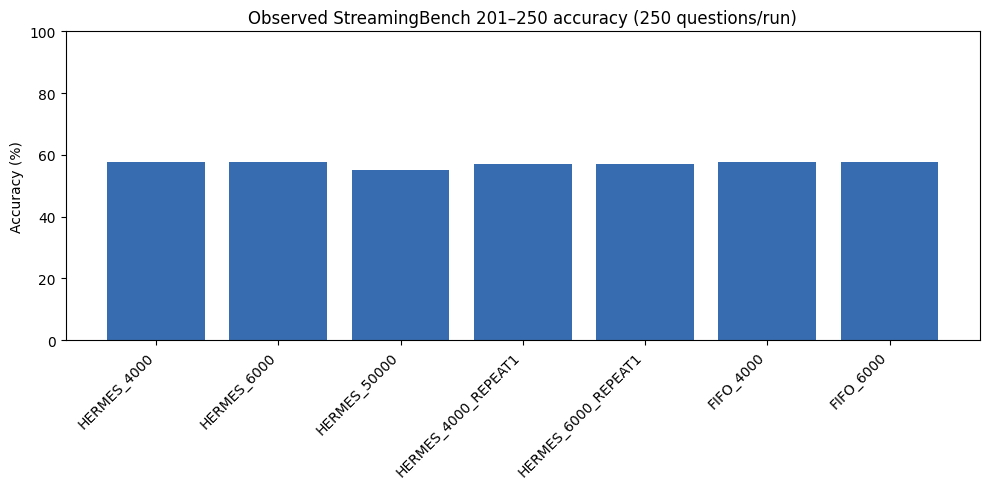

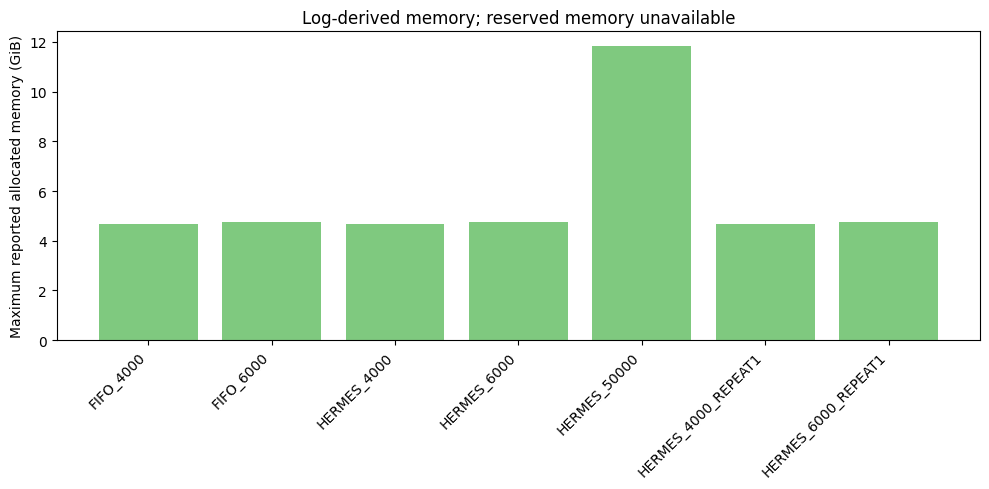

,method,generation,kv_budget,n,correct,accuracy_pct
0,HERMES_4000,preserved_original,4000,250,144,57.6
1,HERMES_6000,preserved_original,6000,250,144,57.6
2,HERMES_50000,preserved_original,50000,250,138,55.2
3,HERMES_4000_REPEAT1,new_repeat1,4000,250,143,57.2
4,HERMES_6000_REPEAT1,new_repeat1,6000,250,143,57.2
5,FIFO_4000,new_control,4000,250,144,57.6
6,FIFO_6000,new_control,6000,250,144,57.6


,method,ttft_n,median_ttft_s,mean_ttft_s,max_reported_allocated_gib,memory_log_count,max_answering_cache,compression_events,compression_marker,encoded_chunks,encoded_frames,outer_elapsed_min_this_session
0,FIFO_4000,250,0.05050,0.05290,4.68903,829,4013,770,FIFO,829,11434,29.39437
1,FIFO_6000,250,0.04855,0.05112,4.73470,829,6013,732,FIFO,829,11434,29.30081
2,HERMES_4000,250,0.04083,0.04050,4.68946,829,4013,770,HERMES,829,11434,28.16541
3,HERMES_6000,250,0.04056,0.03916,4.73532,829,6013,732,HERMES,829,11434,28.25526
4,HERMES_50000,250,0.05192,0.05882,11.83590,829,50013,79,HERMES,829,11434,31.04613
5,HERMES_4000_REPEAT1,250,0.05064,0.05235,4.68946,829,4013,770,HERMES,829,11434,31.44019
6,HERMES_6000_REPEAT1,250,0.04934,0.05003,4.73532,829,6013,732,HERMES,829,11434,31.35321


In [27]:
if EXECUTION_MODE=='full':
    attention_summary=pd.read_csv(WORK/'exports'/'repeat1'/'attention'/'attention_summary.csv')
    attention_layers=pd.read_csv(WORK/'exports'/'repeat1'/'attention'/'attention_per_layer_metrics.csv')
    FINAL_EXPORT=WORK/'exports'/'final';FINAL_FIG=FINAL_EXPORT/'figures'
    FINAL_FIG.mkdir(parents=True,exist_ok=True)
    accuracy_rows=[]
    for kv,d in results50.items():
        accuracy_rows.append({'method':f'HERMES_{kv}','generation':'preserved_original','kv_budget':kv,'n':len(d),'correct':int(d.correct.sum()),'accuracy_pct':100*d.correct.mean()})
    for kv,d in repeat50.items():
        accuracy_rows.append({'method':f'HERMES_{kv}_REPEAT1','generation':'new_repeat1','kv_budget':kv,'n':len(d),'correct':int(d.correct.sum()),'accuracy_pct':100*d.correct.mean()})
    for kv in KV_FIFO:
        d=results[f'FIFO_{kv}']
        accuracy_rows.append({'method':f'FIFO_{kv}','generation':'new_control','kv_budget':kv,'n':len(d),'correct':int(d.correct.sum()),'accuracy_pct':100*d.correct.mean()})
    master_accuracy=pd.DataFrame(accuracy_rows)
    master_accuracy.to_csv(FINAL_EXPORT/'master_accuracy.csv',index=False)
    repeat_eff=[]
    for row in repeat_run_rows:
        kv=row['kv_budget']
        repeat_eff.append(parse_efficiency(f'HERMES_{kv}_REPEAT1',LOGS/f'streamingbench_50_kv{kv}_autodl_repeat1.log',row['elapsed_min_this_session']))
    master_efficiency=pd.concat([efficiency,pd.DataFrame(repeat_eff)],ignore_index=True)
    master_efficiency.to_csv(FINAL_EXPORT/'master_efficiency.csv',index=False)
    paired50.to_csv(FINAL_EXPORT/'original_hermes_paired.csv',index=False)
    stability.to_csv(FINAL_EXPORT/'repeatability_summary.csv',index=False)
    paired_fifo.to_csv(FINAL_EXPORT/'fifo_paired.csv',index=False)
    attention_summary.to_csv(FINAL_EXPORT/'attention_summary.csv',index=False)

    plt.figure(figsize=(10,5))
    plt.bar(master_accuracy.method,master_accuracy.accuracy_pct,color='#386cb0')
    plt.xticks(rotation=45,ha='right');plt.ylim(0,100);plt.ylabel('Accuracy (%)')
    plt.title('Observed StreamingBench 201–250 accuracy (250 questions/run)')
    plt.tight_layout();plt.savefig(FINAL_FIG/'master_accuracy.png',dpi=180);plt.show()
    plot_eff=master_efficiency.dropna(subset=['max_reported_allocated_gib'])
    plt.figure(figsize=(10,5));plt.bar(plot_eff.method,plot_eff.max_reported_allocated_gib,color='#7fc97f')
    plt.xticks(rotation=45,ha='right');plt.ylabel('Maximum reported allocated memory (GiB)')
    plt.title('Log-derived memory; reserved memory unavailable')
    plt.tight_layout();plt.savefig(FINAL_FIG/'master_memory.png',dpi=180);plt.show()

    status={'preserved_and_reanalyzed':[f'HERMES_{k}' for k in KV_BUDGETS],
            'completed_or_reused_new':[f'HERMES_{k}_REPEAT1' for k in KV_REPEAT]+[f'FIFO_{k}' for k in KV_FIFO]+['ATTENTION_DIFFERENTIAL'],
            'failed':[],'skipped':{'native_full_prefix':'known OOM/context limitations; no truncated substitute',
            'component_ablations':'pending matched FIFO interpretation','full_498_video_benchmark':'not selected',
            'other_benchmarks':'not selected'}}
    summary={'created_utc':datetime.now(timezone.utc).isoformat(),'status':status,
      'scope':'StreamingBench 201-250; 50 videos; 250 questions per run; 0.5 FPS',
      'reproduction_repository':str(ROOT),'reproduction_head':REPRO_HEAD,
      'source_verification':SOURCE_VERIFICATION,'hermes_revision':HERMES_SHA,
      'transformers_revision':TF_SHA,'model_snapshot':MODEL_SNAPSHOT.name,'original_inference_rerun':False,
      'accuracy':accuracy_rows,'repeatability':stability.to_dict('records'),
      'fifo_paired':paired_fifo.to_dict('records'),'attention':attention_summary.to_dict('records'),
      'limitations':['Subset results do not establish full-benchmark reproduction.',
        '50K is near-uncompressed HERMES, not native LLaVA.','TTFT is not end-to-end latency.',
        'Reserved GPU memory was not logged.','Runtime is specific to the AutoDL GPU and preserved/new session.',
        'Attention differential uses a text-cache/query test, not a full-video ablation.',
        'Exact discordance tests are exploratory; confidence intervals use video-cluster bootstrap.']}
    (FINAL_EXPORT/'observed_research_summary.json').write_text(json.dumps(summary,indent=2))
    text_summary='# Observed HERMES AutoDL research summary\n\n'
    text_summary+='## Execution status\n\n```json\n'+json.dumps(status,indent=2)+'\n```\n\n'
    text_summary+='## Accuracy\n\n```\n'+master_accuracy.round(4).to_string(index=False)+'\n```\n\n'
    text_summary+='## Repeatability\n\n```\n'+stability.round(4).to_string(index=False)+'\n```\n\n'
    text_summary+='## FIFO paired comparisons\n\n```\n'+paired_fifo.round(4).to_string(index=False)+'\n```\n\n'
    text_summary+='## Efficiency\n\n```\n'+master_efficiency.round(5).to_string(index=False)+'\n```\n\n'
    text_summary+='## Attention differential\n\n```\n'+attention_summary.round(6).to_string(index=False)+'\n```\n\n'
    text_summary+='## Limits\n\n'+'\n'.join('- '+x for x in summary['limitations'])+'\n'
    (FINAL_EXPORT/'observed_research_summary.md').write_text(text_summary)
    display(master_accuracy.round(3));display(master_efficiency.round(5))
else:
    print('Consolidated research exports skipped in smoke mode.')

## 15. Final integrity checks and evidence archive

In [28]:
if EXECUTION_MODE == 'full':
    # Re-read every raw prediction file from disk before packaging.
    for kv in KV_BUDGETS:
        assert len(read_hermes_csv(result_path(kv),50,250)) == 250
        verify_preserved(f'HERMES/results/streamingbench_50_kv{kv}/1_0.csv')
        verify_preserved(f'logs/streamingbench_50_kv{kv}.log')
    for kv in KV_REPEAT: assert len(read_hermes_csv(repeat_result_path(kv),50,250)) == 250
    for kv in KV_FIFO: assert len(read_hermes_csv(fifo_path(kv),50,250)) == 250
    assert len(master_accuracy) == 7 and len(master_efficiency) == 7
    assert len(stability) == 2 and len(paired_fifo) == 4 and len(attention_layers) == 72
    payload = [ANNOTATION_50,PRESERVED_ANNOTATION,FIFO_SCRIPT,ATTENTION_SCRIPT,WORK/'source_provenance.json',
               ORIGINAL_EXPORTS/'run_summary.csv',ORIGINAL_EXPORTS/'provenance.json',ORIGINAL_EXPORTS/'manifest_sha256.csv']
    payload += [x for x in (WORK/'exports').rglob('*') if x.is_file() and x.suffix in {'.csv','.json','.md','.png'}]
    for kv in KV_BUDGETS: payload += [result_path(kv),original_log_path(kv)]
    for kv in KV_REPEAT: payload += [repeat_result_path(kv),LOGS/f'streamingbench_50_kv{kv}_autodl_repeat1.log']
    for kv in KV_FIFO: payload += [fifo_path(kv),LOGS/f'streamingbench_50_kv{kv}_fifo.log']
    payload += [LOGS/'phase1_attention_differential.log']
    payload = sorted(set(x.resolve() for x in payload))
    for path_obj in payload: assert path_obj.is_file() and path_obj.stat().st_size > 0,path_obj
    def archive_name(path_obj):
        path_obj = Path(path_obj).resolve()
        if path_obj == WORK or WORK in path_obj.parents:
            return str(path_obj.relative_to(WORK))
        if path_obj == ROOT or ROOT in path_obj.parents:
            return 'preserved/'+str(path_obj.relative_to(ROOT))
        raise AssertionError(f'Payload outside WORK/ROOT: {path_obj}')
    manifest = pd.DataFrame([{'path':archive_name(x),
        'origin':'generated' if WORK in x.parents else 'preserved',
        'bytes':x.stat().st_size,'sha256':sha256(x)} for x in payload])
    assert not manifest.path.duplicated().any()
    manifest_path = FINAL_EXPORT/'master_manifest_sha256.csv'
    manifest.to_csv(manifest_path,index=False); payload.append(manifest_path.resolve())
    archive = WORK/'HERMES_AutoDL_final_evidence.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for path_obj in sorted(set(payload)): z.write(path_obj,arcname=archive_name(path_obj))
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None
        assert 'exports/final/observed_research_summary.json' in z.namelist()
        assert 'preserved/HERMES/results/streamingbench_50_kv4000/1_0.csv' in z.namelist()
        assert 'preserved/logs/streamingbench_50_kv4000.log' in z.namelist()
    print('FULL SUITE INTEGRITY: PASS')
    print('Evidence archive:',archive)
    print('Archive SHA-256:',sha256(archive))
    print('Review observed_research_summary.md before planning component ablations or generalization.')
else:
    assert 'smoke_d' in globals() and len(smoke_d) == 5
    print('SMOKE WORKFLOW COMPLETE: one video, five predictions validated.')
    print('No full-suite research conclusion or archive is claimed in smoke mode.')

Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv4000/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv4000 parsed-choice/qa_acc mismatches: 0
Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv4000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv4000.log
Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv6000/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv6000 parsed-choice/qa_acc mismatches: 0
Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv6000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv6000.log
Annotation audit: /root/autodl-tmp/HERMES-reproduction/HERMES/results/streamingbench_50_kv50000/1_0.csv: 250/250 rows matched to source
streamingbench_50_kv50000 parsed-choice/qa_acc mismatches: 0
Preserved SHA-256: PASS | HERMES/results/streamingbench_50_kv50000/1_0.csv
Preserved SHA-256: PASS | logs/streamingbench_50_kv50000.log
Annotatio